### Gießroboter – Lösung Schritt für Schritt

*44. Bundeswettbewerb Informatik (2025/2026), 2. Runde, Aufgabe 2*

Ein großer botanischer Garten möchte die Bewässerung seiner seltenen und wertvollen Bäume sicherstellen. Dazu möchte die
Betreiberfirma des Gartens neuartige Gießroboter verwenden. Jeder Roboter soll dazu eine festgelegte Route befahren und dabei die
Bäume entlang dieser Route bewässern. Für jeden der Roboter gibt es eine Ladestation, an dem seine Route startet und endet. Da die
Akkukapazitäten der Roboter begrenzt sind, dürfen die Routenlängen eine für alle Roboter gleiche Maximallänge nicht überschreiten.

Weil die Roboter sehr teuer sind, möchten die Betreiber mit möglichst wenigen Geräten auskommen. Kannst du ihnen dabei helfen?

#### Aufgabe

Schreibe ein Programm, das die Maximallänge der Routen sowie die Positionen der Bäume in der Gartenanlage einliest. Dein Programm soll
dann die Anzahl der Roboter sowie deren Routen bestimmen, sodass jeder Baum bewässert wird. Versuche dabei, die Anzahl der Roboter
möglichst klein zu halten.

Wende dein Programm mindestens auf alle Beispiele an, die du auf den BWINF-Webseiten findest, und dokumentiere die Ergebnisse.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `roboter01.txt` bis `roboter11.txt`. Jede Datei beschreibt den Plan eines botanischen Gartens:

1. Zeile: die maximale Routenlänge.
2. Zeile: die Anzahl der Bäume.
3. Dann je Baum eine Zeile mit drei Zahlen: der ID, der x-Koordinate und der y-Koordinate.

```
60
3
1 10 82
2 42 25
3 2 128
```

Das ist ein Garten mit drei Bäumen. Die Routen dürfen höchstens 60 Einheiten lang sein. Der erste Baum hat die Koordinaten (10|82).

#### Ausgabeformat

Die Ausgabe muss dieses Format haben (`roboter00_out.txt` zeigt ein Beispiel):

1. Zeile: Anzahl der benötigten Roboter
2. Zeile: die in der Eingabedatei vorgegebene maximale Routenlänge
3. Dann für jeden Roboter drei Zeilen:
   - die Länge seiner Route (auf eine ganze Zahl aufgerundet),
   - die Koordinaten seiner Ladestation,
   - die Abfolge der besuchten Bäume als IDs, durch Leerzeichen getrennt.

Für alle Beispiele müssen mindestens die 1. und 2. Zeile der Ausgabe in der Dokumentation stehen, für `roboter01`, `roboter02`,
`roboter05` und `roboter06` die vollständige Ausgabe.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Gute Modellierung:** Die Ladestation einer Route kann man immer **an den ersten Baum der Route** legen. Dann ist die Route ein
  geschlossener Weg (ein *Kreis*) durch ihre Bäume, und die Länge ist die Summe aller Teilstücke einschließlich des Wegs vom letzten
  zurück zum ersten Baum.
- **Rundreise (TSP):** Die Reihenfolge der Bäume einer Route bestimmt ihre Länge. Eine möglichst kurze Reihenfolge zu finden ist das
  Problem des Handlungsreisenden. Dafür gibt es keine schnelle exakte Lösung, aber gute Näherungen.
- **Greedy-Verfahren (gieriges Verfahren):** Man entscheidet in jedem Schritt für die Möglichkeit, die gerade am besten aussieht. Hier:
  Welcher Baum kommt als Nächstes in die Route?
- **Einfügen mit Umweg:** Ein neuer Baum wird dort in die Route eingefügt, wo er den **kleinsten Umweg** verursacht.
- **Lokale Verbesserung (2-opt):** Man tauscht in einer Route zwei Kanten aus, wenn die Route dadurch kürzer wird. Das beseitigt zum
  Beispiel Kreuzungen.
- **Gitter für die Nachbarschaft:** Statt für einen Baum alle anderen Bäume anzuschauen, sucht man nur in der Umgebung. Dafür
  teilt man den Garten in Quadrate ein und merkt sich in einem `dict`, welche Bäume in welchem Quadrat liegen.
- **Heuristik:** Die Aufgabe ist NP-schwer, man kann also nicht erwarten, immer die beste Lösung zu finden. Wir suchen eine **gute**
  Lösung und verbessern sie danach, so gut es geht.

**Nützliche Funktionen und Bibliotheken**
- `math.sqrt` und `math.ceil`, `dict`, `set`, Tupel `(x, y)`
- `liste.sort()` sortiert eine Liste aus Tupeln nach dem ersten Eintrag (bei Gleichstand nach dem zweiten)
- Listen als Kreis: `route[(k + 1) % len(route)]` ist der Nachfolger, und nach dem letzten Eintrag kommt wieder der erste
- `matplotlib.pyplot` für die Zeichnung (optional)

## Die Idee

1. **Eine Route bauen:** Man beginnt bei einem Baum und fügt immer den Baum hinzu, der die Route am wenigsten verlängert, solange die
   Maximallänge nicht überschritten wird. Nach jedem Hinzufügen wird die Route mit 2-opt verkürzt, damit mehr Platz bleibt.
2. **Wo anfangen?** Von außen nach innen: Der Baum, der am weitesten von der Mitte der Anlage entfernt ist, bekommt die erste Route,
   dann der nächste noch nicht bewässerte Baum von außen und so weiter. Dann bleiben am Ende keine einzelnen Bäume am Rand übrig, die
   eine ganze Route für sich brauchen. Damit eine Route nicht zu früh nach innen wandert, zählt beim Auswählen auch, wie weit ein Baum
   von der Mitte entfernt ist.
3. **Mehrere Versuche:** Das Gewicht dieses Abstands probieren wir mit zwei Werten aus und nehmen die bessere Einteilung.
4. **Routen auflösen:** Danach versuchen wir, eine ganze Route zu streichen, indem wir ihre Bäume in die Routen der Nachbarschaft
   einfügen. Klappt das für alle Bäume, ist ein Roboter gespart.

## Schritt 1: Die Eingabe lesen

Wir speichern die Bäume als Liste von Tupeln `(x, y)`. Der Baum mit der ID `i + 1` steht an Position `i` der Liste (die IDs in den
Beispielen laufen von 1 bis n ohne Lücken). In der Ausgabe rechnen wir wieder auf IDs um.

In [ ]:
def lies_garten(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        zeilen = []
        for zeile in f.read().splitlines():
            if zeile.split():                       # leere Zeilen überspringen
                zeilen.append(zeile.split())
    lmax = int(zeilen[0][0])
    n = int(zeilen[1][0])
    baeume = []
    for i in range(n):
        baeume.append((int(zeilen[2 + i][1]), int(zeilen[2 + i][2])))
    return lmax, baeume


lmax, baeume = lies_garten('beispieldaten/roboter01.txt')
print('Maximale Routenlänge:', lmax)
print('Bäume:', len(baeume))
print(baeume)

Maximale Routenlänge: 175
Bäume: 13
[(68, 753), (104, 743), (95, 704), (67, 719), (110, 769), (124, 713), (154, 678), (169, 696), (156, 728), (113, 675), (80, 677), (142, 754), (53, 684)]


## Schritt 2: Die Länge einer Route

Eine Route ist eine Liste von Baumnummern (Positionen in `baeume`). Die Ladestation liegt am ersten Baum der Route.

**Warum dort?** Wo auch immer die Ladestation liegt: Der Roboter fährt von ihr zum ersten Baum und vom letzten Baum zu ihr zurück.
Nach der **Dreiecksungleichung** ist der direkte Weg vom letzten zum ersten Baum nie länger als der Umweg über die Ladestation. Die
Ladestation am ersten Baum (oder irgendwo auf der Strecke dazwischen) ist also immer mindestens so gut. Dann beginnt und endet die
Route am selben Baum, und ihre Länge ist die Länge des **Kreises** durch alle Bäume.

**Hindurchfahren und mehrfach bewässern:** Die Aufgabe erlaubt, durch Bäume hindurchzufahren und Bäume mehrfach zu bewässern. Das
braucht unser Modell nicht eigens: Geradeaus an einem Baum vorbei zu fahren ist in der Luftlinie zwischen zwei Bäumen schon
enthalten, und ein Baum, der in zwei Routen vorkommt, bringt keinen Vorteil.

In [ ]:
from math import sqrt, ceil


def abstand(baeume, i, j):
    return sqrt((baeume[i][0] - baeume[j][0]) ** 2 + (baeume[i][1] - baeume[j][1]) ** 2)


def route_laenge(baeume, route):
    summe = 0.0
    for k in range(len(route)):
        summe = summe + abstand(baeume, route[k], route[(k + 1) % len(route)])   # nach dem letzten wieder der erste
    return summe


route = [0, 1, 2, 3]
print('Länge der Route', route, ':', route_laenge(baeume, route))
print('aufgerundet:', ceil(route_laenge(baeume, route)), ', erlaubt:', lmax)

Länge der Route [0, 1, 2, 3] : 143.1675386288449
aufgerundet: 144 , erlaubt: 175


## Schritt 3: Einfügen mit kleinstem Umweg

Soll der Baum `c` in eine Route eingefügt werden, kommt er zwischen zwei aufeinanderfolgende Bäume `a` und `b`. Dort ersetzt der Weg
`a → c → b` den direkten Weg `a → b`. Der **Umweg** ist

`umweg = abstand(a, c) + abstand(c, b) − abstand(a, b)`.

Wir probieren alle Stellen der Route aus und nehmen die mit dem kleinsten Umweg. `beste_stelle` gibt den Umweg und die Position
zurück, an der man `c` mit `route.insert(position, c)` einfügt. Eine Route aus nur einem Baum hat keine Kante: Dann ist der Umweg
die Strecke hin und zurück.

In [ ]:
def beste_stelle(baeume, route, c):
    if len(route) == 1:
        return 2 * abstand(baeume, route[0], c), 1
    bester_umweg = None
    beste_position = 0
    for k in range(len(route)):
        a = route[k]
        b = route[(k + 1) % len(route)]
        umweg = abstand(baeume, a, c) + abstand(baeume, c, b) - abstand(baeume, a, b)
        if bester_umweg is None or umweg < bester_umweg:
            bester_umweg = umweg
            beste_position = k + 1                 # c kommt hinter a
    return bester_umweg, beste_position


route = [0, 1, 2]
for c in [3, 4, 5]:
    umweg, position = beste_stelle(baeume, route, c)
    print('Baum', c, ': Umweg', round(umweg, 2), ', einfügen an Position', position)

Baum 3 : Umweg 9.83 , einfügen an Position 3
Baum 4 : Umweg 34.26 , einfügen an Position 1
Baum 5 : Umweg 26.39 , einfügen an Position 2


## Schritt 4: Eine Route verkürzen (2-opt)

Die Reihenfolge, in der wir die Bäume einfügen, ist nicht immer die beste. Zum Beispiel kann sich die Route selbst **kreuzen**. Dann
ist sie unnötig lang. Der Trick: Wir nehmen zwei Kanten `a → b` und `c → e` der Route. Statt dieser beiden fahren wir `a → c` und
`b → e`, und das Stück zwischen `b` und `c` durchläuft man dafür rückwärts. Ist die Summe der neuen Kanten kürzer als die der alten,
behalten wir die Änderung. Das wiederholen wir für alle Paare von Kanten, bis sich nichts mehr verbessert.

Das Beispiel hat vier Bäume an den Ecken eines Quadrats, aber in einer Reihenfolge, die über Kreuz führt.

In [ ]:
def zwei_opt(baeume, route):
    n = len(route)
    if n < 4:
        return route
    verbessert = True
    while verbessert:
        verbessert = False
        for i in range(n - 1):
            for j in range(i + 2, n):
                if i == 0 and j == n - 1:
                    continue                      # dieselbe Kante wie (n-1, 0)
                a = route[i]
                b = route[i + 1]
                c = route[j]
                e = route[(j + 1) % n]
                alt = abstand(baeume, a, b) + abstand(baeume, c, e)
                neu = abstand(baeume, a, c) + abstand(baeume, b, e)
                if neu < alt - 0.000000001:
                    route[i + 1:j + 1] = route[i + 1:j + 1][::-1]       # das Stück b ... c umdrehen
                    verbessert = True
    return route


ecken = [(0, 0), (10, 0), (0, 10), (10, 10)]
kreuz = [0, 3, 1, 2]                               # (0,0) -> (10,10) -> (10,0) -> (0,10): kreuzt sich
print('vorher:', kreuz, round(route_laenge(ecken, kreuz), 2))
kreuz = zwei_opt(ecken, kreuz)
print('nachher:', kreuz, round(route_laenge(ecken, kreuz), 2))

vorher: [0, 3, 1, 2] 48.28
nachher: [0, 1, 3, 2] 40.0


Aus der Route mit zwei Diagonalen wird der Umfang des Quadrats (Länge 40 statt etwa 48,3). Der erste Baum der Route bleibt dabei
immer derselbe, denn wir drehen nur Stücke **hinter** Position `i`. Das ist wichtig, weil dort die Ladestation liegt.

## Schritt 5: Nachbarschaft mit einem Gitter

Bei 20 000 Bäumen wäre es viel zu langsam, für jeden Baum alle anderen anzuschauen. Wir nutzen eine Beobachtung: **Alle Bäume einer
Route liegen höchstens `lmax / 2` von jedem anderen Baum der Route entfernt**, denn der Roboter muss zu dem Baum hin und wieder zurück.
Als Nachbarn eines Baums brauchen wir also nur Bäume im Abstand höchstens `lmax / 2`.

Dafür teilen wir den Garten in Quadrate der Kantenlänge `lmax / 2` ein. Das Quadrat eines Baums bekommen wir durch ganzzahliges Teilen
der Koordinaten: `(int(x // zelle), int(y // zelle))`. In einem `dict` `gitter` merken wir uns für jedes Quadrat die Liste der Bäume
darin. Die Nachbarn eines Baums liegen dann im eigenen oder in einem der acht umliegenden Quadrate.

Dabei berechnen wir gleich, was später gebraucht wird: den **Mittelpunkt** der Anlage (Mittelwert der Koordinaten), den Abstand jedes
Baums dazu in `mitte` und die Reihenfolge `reihenfolge`, in der die Bäume als Startbaum drankommen: **absteigend nach dem Abstand zur
Mitte**. Dafür bauen wir Tupel `(-abstand, nummer)` und sortieren sie. Mit dem Minus kommt der größte Abstand zuerst. Alles zusammen
speichern wir in einem `dict` `garten`, damit wir es leicht an Funktionen weitergeben können.

In [ ]:
def bereite_vor(lmax, baeume):
    zelle = lmax / 2
    gitter = {}
    for i in range(len(baeume)):
        schluessel = (int(baeume[i][0] // zelle), int(baeume[i][1] // zelle))
        if schluessel not in gitter:
            gitter[schluessel] = []
        gitter[schluessel].append(i)
    mx = 0.0
    my = 0.0
    for x, y in baeume:
        mx = mx + x / len(baeume)
        my = my + y / len(baeume)
    mitte = []
    paare = []
    for i in range(len(baeume)):
        m = sqrt((baeume[i][0] - mx) ** 2 + (baeume[i][1] - my) ** 2)
        mitte.append(m)
        paare.append((-m, i))
    paare.sort()                                    # Tupel werden nach dem ersten Eintrag sortiert
    reihenfolge = []
    for m, i in paare:
        reihenfolge.append(i)
    return {'lmax': lmax, 'baeume': baeume, 'zelle': zelle, 'gitter': gitter, 'mitte': mitte, 'reihenfolge': reihenfolge}


def nachbarn(garten, i):
    """Alle Bäume im Abstand höchstens lmax / 2 von Baum i (ohne i selbst)."""
    baeume = garten['baeume']
    zelle = garten['zelle']
    cx = int(baeume[i][0] // zelle)
    cy = int(baeume[i][1] // zelle)
    ergebnis = []
    for gx in [cx - 1, cx, cx + 1]:
        for gy in [cy - 1, cy, cy + 1]:
            if (gx, gy) in garten['gitter']:
                for c in garten['gitter'][(gx, gy)]:
                    if c != i and abstand(baeume, i, c) <= garten['lmax'] / 2:
                        ergebnis.append(c)
    return ergebnis


garten = bereite_vor(lmax, baeume)
print('Quadrate im Gitter:', len(garten['gitter']))
print('Reihenfolge der Startbäume (von außen nach innen):', garten['reihenfolge'])
print('Nachbarn von Baum 0:', nachbarn(garten, 0))

Quadrate im Gitter: 4
Reihenfolge der Startbäume (von außen nach innen): [12, 7, 6, 0, 4, 11, 10, 8, 3, 9, 1, 2, 5]
Nachbarn von Baum 0: [10, 12, 3, 1, 2, 4, 5, 11]


Bei `roboter01.txt` mit `lmax = 175` und 13 Bäumen hat Baum 0 acht der zwölf anderen Bäume als Nachbarn. Bei den großen Beispielen ist
es nur ein kleiner Teil der Bäume.

## Schritt 6: Eine Route bauen

Jetzt kommt das Herzstück. `baue_route(garten, start, frei, eta)` baut die Route, die bei `start` beginnt. `frei[i]` ist `True`,
solange Baum `i` noch nicht in einer Route liegt.

1. Die **Kandidaten** sind die freien Nachbarn des Startbaums. Nur sie können in der Route landen.
2. Für jeden Kandidaten berechnen wir den kleinsten Umweg. Passt er nicht mehr (die Route würde zu lang), **scheidet er für diese Route
   aus**. Das spart viel Rechenzeit, denn mit wachsender Route kommt kaum ein Baum wieder in Frage, der gerade nicht gepasst hat.
3. Von den übrigen nehmen wir den Kandidaten mit der kleinsten **Punktzahl** `umweg − eta · abstand_zur_mitte`. Ein kleiner Umweg ist
   gut. Der Abzug mit `eta` sorgt dafür, dass bei ähnlichem Umweg der Baum bevorzugt wird, der weiter außen liegt. So „frisst“ sich die
   Route nicht in die Mitte, wo später noch Platz für die nächsten Routen gebraucht wird.
4. Wir fügen den Baum ein und verkürzen die Route mit 2-opt, sobald sie mindestens 4 Bäume hat.
5. Das wiederholen wir, bis kein Kandidat mehr passt.

Die Länge einer Route halten wir dabei immer ein winziges Stück unter `lmax` (`SICHER`), damit Rundungsfehler bei den Kommazahlen nie
dazu führen, dass eine Route doch um einen Bruchteil zu lang ist.

In [ ]:
SICHER = 0.000001


def baue_route(garten, start, frei, eta):
    baeume = garten['baeume']
    lmax = garten['lmax']
    mitte = garten['mitte']
    route = [start]
    laenge = 0.0
    frei[start] = False
    kandidaten = []
    for c in nachbarn(garten, start):
        if frei[c]:
            kandidaten.append(c)
    while len(kandidaten) > 0:
        bester = None
        passende = []
        for c in kandidaten:
            umweg, position = beste_stelle(baeume, route, c)
            if laenge + umweg <= lmax - SICHER:
                passende.append(c)                  # passt noch: bleibt Kandidat
                punkte = umweg - eta * mitte[c]
                if bester is None or punkte < bester[0]:
                    bester = (punkte, c, position)
        kandidaten = passende
        if bester is None:
            break
        punkte, c, position = bester
        route.insert(position, c)
        frei[c] = False
        kandidaten.remove(c)
        if len(route) >= 4:
            route = zwei_opt(baeume, route)
        laenge = route_laenge(baeume, route)
    return route


frei = [True] * len(baeume)
route = baue_route(garten, garten['reihenfolge'][0], frei, 0.2)
print('erste Route:', route, ' Länge', round(route_laenge(baeume, route), 2), ' erlaubt', lmax)

erste Route: [12, 3, 2, 9, 10]  Länge 164.55  erlaubt 175


Die Route beginnt bei Baum 12 (ID 13 mit den Koordinaten (53|684)), dem Baum, der am weitesten von der Mitte der Anlage entfernt ist.
Sie nimmt der Reihe nach passende Bäume mit auf, bis die erlaubte Länge ausgeschöpft ist. Die Route ist 164,55 lang, erlaubt sind 175.

## Schritt 7: Alle Routen, Prüfung und erste Lösung

Jetzt gehen wir die Bäume in der Reihenfolge von außen nach innen durch. Ist ein Baum noch frei, beginnt dort eine neue Route. Dann
sind am Ende alle Bäume bewässert, denn jeder Baum ist entweder schon in einer Route oder bekommt eine.

Bevor wir den Lösungen vertrauen, schreiben wir eine **Prüffunktion**: Liegt jeder Baum in mindestens einer Route, und ist jede
Route höchstens `lmax` lang? Das prüfen wir bei allen Ergebnissen.

In [ ]:
def erste_loesung(garten, eta):
    frei = [True] * len(garten['baeume'])
    routen = []
    for start in garten['reihenfolge']:
        if frei[start]:
            routen.append(baue_route(garten, start, frei, eta))
    return routen


def pruefe(garten, routen):
    gewaessert = [False] * len(garten['baeume'])
    for route in routen:
        if route_laenge(garten['baeume'], route) > garten['lmax']:
            return False
        for baum in route:
            gewaessert[baum] = True
    return not (False in gewaessert)


routen = erste_loesung(garten, 0.2)
print(len(routen), 'Routen, gültig:', pruefe(garten, routen))
for route in routen:
    print(round(route_laenge(baeume, route), 1), route)

3 Routen, gültig: True
164.5 [12, 3, 2, 9, 10]
139.4 [7, 8, 5, 6]
157.2 [0, 4, 11, 1]


Für `roboter01.txt` genügen drei Roboter. Die offiziellen Lösungshinweise kommen mit ihren Verfahren ebenfalls auf 3. Ob es mit
2 Robotern ginge, kann unser Verfahren nicht sagen: Es findet eine gute Lösung, beweist aber nicht, dass sie die beste ist.

## Schritt 8: Routen auflösen

Die Greedy-Lösung hat manchmal eine Route mehr als nötig. Wir versuchen deshalb, **eine Route zu streichen**: Jeden ihrer Bäume
fügen wir, wenn möglich, in eine andere Route der Nachbarschaft ein (mit kleinstem Umweg und nur, wenn diese Route dadurch nicht zu
lang wird). Klappt das für alle Bäume, ist die Route überflüssig und ein Roboter gespart. Klappt es für einen Baum nicht, nehmen wir
alles wieder zurück (`alt` merkt sich die Zustände der veränderten Routen).

Die Routen in der Nachbarschaft eines Baums finden wir über `nachbarn`: Jede Route, in der ein Nachbar liegt. `besitzer[i]` sagt,
in welcher Route Baum `i` liegt. `set` sammelt die Routen ohne Doppelte. Wir fangen mit den kleinsten Routen an, denn
die lassen sich am leichtesten auflösen. Nach jedem Einfügen verkürzen wir die Route mit 2-opt und rechnen ihre Länge neu aus.

Das wiederholen wir, solange noch eine Route aufgelöst werden kann.

In [ ]:
def loese_route_auf(garten, routen, laengen, besitzer, lebt, k):
    baeume = garten['baeume']
    lmax = garten['lmax']
    alt = {}                                           # Route -> (Kopie der Route, alte Länge)
    for t in routen[k]:
        ziele = set()
        for c in nachbarn(garten, t):
            j = besitzer[c]
            if j != k and lebt[j]:
                ziele.add(j)
        bestes = None
        for j in sorted(ziele):
            umweg, position = beste_stelle(baeume, routen[j], t)
            if laengen[j] + umweg <= lmax - SICHER and (bestes is None or umweg < bestes[0]):
                bestes = (umweg, j, position)
        if bestes is None:                             # t passt nirgends hin: alles zurücknehmen
            for j in alt:
                routen[j] = alt[j][0]
                laengen[j] = alt[j][1]
            for baum in routen[k]:
                besitzer[baum] = k
            return False
        umweg, j, position = bestes
        if j not in alt:
            alt[j] = (routen[j][:], laengen[j])
        routen[j].insert(position, t)
        besitzer[t] = j
        if len(routen[j]) >= 4:
            routen[j] = zwei_opt(baeume, routen[j])
        laengen[j] = route_laenge(baeume, routen[j])
    lebt[k] = False
    return True


def verbessere(garten, routen):
    baeume = garten['baeume']
    routen = [route[:] for route in routen]            # Kopien, die Eingabe bleibt unverändert
    laengen = []
    besitzer = [0] * len(baeume)
    for k in range(len(routen)):
        laengen.append(route_laenge(baeume, routen[k]))
        for t in routen[k]:
            besitzer[t] = k
    lebt = [True] * len(routen)
    geschafft = True
    while geschafft:
        geschafft = False
        reihe = []
        for k in range(len(routen)):
            reihe.append((len(routen[k]), k))
        reihe.sort()                                   # kleinste Routen zuerst
        for anzahl, k in reihe:
            if lebt[k] and loese_route_auf(garten, routen, laengen, besitzer, lebt, k):
                geschafft = True
    uebrig = []
    for k in range(len(routen)):
        if lebt[k]:
            uebrig.append(routen[k])
    return uebrig


lmax, baeume = lies_garten('beispieldaten/roboter06.txt')
garten = bereite_vor(lmax, baeume)
routen = erste_loesung(garten, 0.2)
print('roboter06 nach dem Greedy:', len(routen), 'Routen')
routen = verbessere(garten, routen)
print('roboter06 nach dem Auflösen:', len(routen), 'Routen, gültig:', pruefe(garten, routen))

roboter06 nach dem Greedy: 7 Routen
roboter06 nach dem Auflösen: 6 Routen, gültig: True


Mit `eta = 0.2` spart das Auflösen bei `roboter06.txt` einen Roboter.

## Schritt 9: Das Gewicht `eta` und das gesamte Verfahren

Wie groß `eta` sein soll, hängt vom Garten ab. Ist `eta` 0, zählt nur der Umweg, bei größerem `eta` bevorzugt man Bäume am Rand. Wir
probieren zwei Werte, `0.2` und `0.5`, und nehmen die Einteilung mit weniger Routen. Danach wird sie mit `verbessere` verbessert.
Die Funktion `loese` gibt die fertigen Routen zusammen mit der Zahl der Roboter nach dem Greedy-Aufbau zurück.

In [ ]:
ETAS = [0.2, 0.5]


def loese(garten):
    beste = None
    for eta in ETAS:
        routen = erste_loesung(garten, eta)
        if beste is None or len(routen) < len(beste):
            beste = routen
    greedy = len(beste)
    fertig = verbessere(garten, beste)
    return fertig, greedy


lmax, baeume = lies_garten('beispieldaten/roboter02.txt')
garten = bereite_vor(lmax, baeume)
routen, greedy = loese(garten)
print('roboter02: Greedy', greedy, 'Roboter, am Ende', len(routen), ', gültig:', pruefe(garten, routen))

roboter02: Greedy 8 Roboter, am Ende 8 , gültig: True


## Schritt 10: Alle Beispiele

Jetzt lassen wir das Verfahren auf alle elf Beispiele los. Für jedes Beispiel steht die Anzahl der Roboter nach dem Greedy-Aufbau
(mit dem besseren `eta`) und am Ende. Außerdem prüfen wir jedes Ergebnis mit `pruefe`. Die Beispiele `roboter07` und `roboter11`
haben viele tausend Bäume, die Zelle braucht deshalb etwas Zeit (im Browser deutlich länger als auf einem installierten Python).

In [ ]:
ergebnisse = {}
for nr in range(1, 12):
    dateiname = 'beispieldaten/roboter' + str(nr).rjust(2, '0') + '.txt'
    lmax, baeume = lies_garten(dateiname)
    garten = bereite_vor(lmax, baeume)
    routen, greedy = loese(garten)
    ergebnisse[nr] = (garten, routen)
    print('roboter' + str(nr).rjust(2, '0') + '.txt:', str(len(baeume)).rjust(5), 'Bäume, lmax', str(lmax).rjust(4),
          '-> Greedy', str(greedy).rjust(4), ', am Ende', str(len(routen)).rjust(4), 'Roboter, gültig:', pruefe(garten, routen))

roboter01.txt:    13 Bäume, lmax  175 -> Greedy    3 , am Ende    3 Roboter, gültig: True
roboter02.txt:    18 Bäume, lmax  175 -> Greedy    8 , am Ende    8 Roboter, gültig: True
roboter03.txt:   500 Bäume, lmax  300 -> Greedy   57 , am Ende   57 Roboter, gültig: True
roboter04.txt:   200 Bäume, lmax  100 -> Greedy   37 , am Ende   37 Roboter, gültig: True
roboter05.txt:   200 Bäume, lmax 1400 -> Greedy    3 , am Ende    3 Roboter, gültig: True
roboter06.txt:   200 Bäume, lmax  700 -> Greedy    6 , am Ende    6 Roboter, gültig: True
roboter07.txt:  4978 Bäume, lmax  300 -> Greedy  166 , am Ende  166 Roboter, gültig: True
roboter08.txt:  4978 Bäume, lmax  100 -> Greedy  531 , am Ende  531 Roboter, gültig: True
roboter09.txt:   400 Bäume, lmax  300 -> Greedy   45 , am Ende   45 Roboter, gültig: True
roboter10.txt:  4996 Bäume, lmax  300 -> Greedy  435 , am Ende  435 Roboter, gültig: True
roboter11.txt: 19989 Bäume, lmax  300 -> Greedy 1742 , am Ende 1742 Roboter, gültig: True


**Ergebnis und Vergleich:** Die offiziellen Lösungshinweise erreichen mit ihren verbesserten Verfahren (zusätzlich exakte Rundreisen,
Umverteilen der Bäume) diese Zahlen:

| Beispiel | unser Ergebnis | Lösungshinweise |
|---|---|---|
| roboter01 | 3 | 3 |
| roboter02 | 8 | 8 |
| roboter03 | 57 | 55 |
| roboter04 | 37 | 35 |
| roboter05 | 3 | 3 |
| roboter06 | 6 | 6 |
| roboter07 | 166 | 155 |
| roboter08 | 531 | 522 |
| roboter09 | 45 | 44 |
| roboter10 | 435 | 422 |
| roboter11 | 1742 | 1699 |

Bei den kleinen Beispielen (01, 02, 05, 06) sind wir genauso gut, bei den anderen brauchen wir etwas mehr Roboter, bei den großen
etwa 2 bis 7 Prozent. Für ein einfaches Verfahren ist das ein ordentliches Ergebnis. Nach der Wahl des besseren `eta` bringt das
Auflösen von Routen bei diesen Beispielen keine weitere Verbesserung mehr (Greedy und „am Ende“ sind gleich). Mit dem schlechteren `eta`
allein dagegen schon, wie Schritt 8 bei `roboter06` zeigt. Wie man das Verfahren weiter verbessern kann, steht unter „Für Neugierige“.

## Schritt 11: Die Ausgabe im vorgeschriebenen Format

Die Ausgabe hat in der 1. Zeile die Zahl der Roboter, in der 2. Zeile die maximale Länge, und dann für jede Route drei Zeilen: die
auf eine ganze Zahl **aufgerundete** Länge, die Koordinaten der Ladestation (der erste Baum der Route) und die IDs der Bäume. Zur
Umrechnung von der Position in `baeume` auf die ID addieren wir 1.

Hier die vollständigen Ausgaben für `roboter01` und `roboter02`:

In [ ]:
def ausgabe_text(garten, routen):
    zeilen = [str(len(routen)), str(garten['lmax'])]
    for route in routen:
        zeilen.append(str(ceil(route_laenge(garten['baeume'], route))))
        start = garten['baeume'][route[0]]
        zeilen.append(str(start[0]) + ' ' + str(start[1]))
        ids = []
        for baum in route:
            ids.append(str(baum + 1))
        zeilen.append(' '.join(ids))
    return '\n'.join(zeilen)


for nr in [1, 2]:
    garten, routen = ergebnisse[nr]
    print('roboter' + str(nr).rjust(2, '0') + '_out.txt:')
    print(ausgabe_text(garten, routen))
    print()

roboter01_out.txt:
3
175
165
53 684
13 4 3 10 11
140
169 696
8 9 6 7
158
68 753
1 5 12 2

roboter02_out.txt:
8
175
0
472 789
18
0
393 712
17
0
291 638
16
155
49 607
14 13
150
68 753
1 5 2 4
147
171 607
15 7
134
80 677
11 10 6 3
129
142 754
12 8 9



Die vollständige Ausgabe für alle Beispiele schreibt man mit `open(..., 'w')` in Dateien, zum Beispiel:

```python
with open('roboter01_out.txt', 'w', encoding='utf-8') as f:
    f.write(ausgabe_text(garten, routen))
```

Die Ausgaben für `roboter05` und `roboter06`, die laut Aufgabe ebenfalls vollständig in der Dokumentation stehen sollen:

In [ ]:
for nr in [5, 6]:
    garten, routen = ergebnisse[nr]
    print('roboter' + str(nr).rjust(2, '0') + '_out.txt:')
    print(ausgabe_text(garten, routen))
    print()

roboter05_out.txt:
3
1400
1397
782 250
40 38 53 57 58 39 68 55 46 109 120 125 102 110 106 126 133 118 108 131 114 124 128 116 104 121 127 105 130 117 132 107 113 122 112 111 103 129 134 41 51 52 66 61 44 47 60 36 62 67 59 50 65 43 63 56 54 35 37 64 45 48 42 49
1380
155 716
14 15 20 17 25 6 9 24 27 19 29 11 16 173 189 174 177 178 199 182 170 180 181 193 183 79 75 80 91 85 101 76 87 84 90 81 70 88 69 96 93 82 99 71 78 97 74 95 94 92 98 73 86 83 77 197 191 176 184 190 196 171 169 187 192 172 186 168 185 195 4 198 200 194 188 175 179 5 30 2 23 12 33 28 13 18 10 3 8 7 32 21 1 26 22 31 34
1090
217 376
72 89 123 119 115 159 158 156 135 143 165 166 154 139 149 151 137 163 160 148 157 140 145 146 162 136 147 161 155 142 164 153 144 167 141 138 150 152 100

roboter06_out.txt:
6
700
566
782 250
40 38 53 57 58 39 68 55 46 51 52 66 61 44 47 45 48 64 37 35 65 60 36 62 41 67 59 50 43 63 56 54 42 49
695
155 716
14 20 15 24 27 19 29 11 16 173 189 174 177 178 199 182 170 180 181 193 191 176 184 190 196 

Zum Schluss die ersten beiden Zeilen (Anzahl Roboter und maximale Länge) für alle Beispiele, die laut Aufgabe überall in der
Dokumentation stehen müssen:

In [ ]:
for nr in range(1, 12):
    garten, routen = ergebnisse[nr]
    erste_zeilen = ausgabe_text(garten, routen).split('\n')[:2]
    print('roboter' + str(nr).rjust(2, '0') + ':', erste_zeilen[0], 'Roboter, maximale Länge', erste_zeilen[1])

roboter01: 3 Roboter, maximale Länge 175
roboter02: 8 Roboter, maximale Länge 175
roboter03: 57 Roboter, maximale Länge 300
roboter04: 37 Roboter, maximale Länge 100
roboter05: 3 Roboter, maximale Länge 1400
roboter06: 6 Roboter, maximale Länge 700
roboter07: 166 Roboter, maximale Länge 300
roboter08: 531 Roboter, maximale Länge 100
roboter09: 45 Roboter, maximale Länge 300
roboter10: 435 Roboter, maximale Länge 300
roboter11: 1742 Roboter, maximale Länge 300


## Schritt 12: Die Routen als Bild

Zur Kontrolle zeichnen wir die Routen: Jede Route hat eine eigene Farbe, die Bäume sind kleine Punkte, die Ladestation ist größer
und schwarz umrandet.

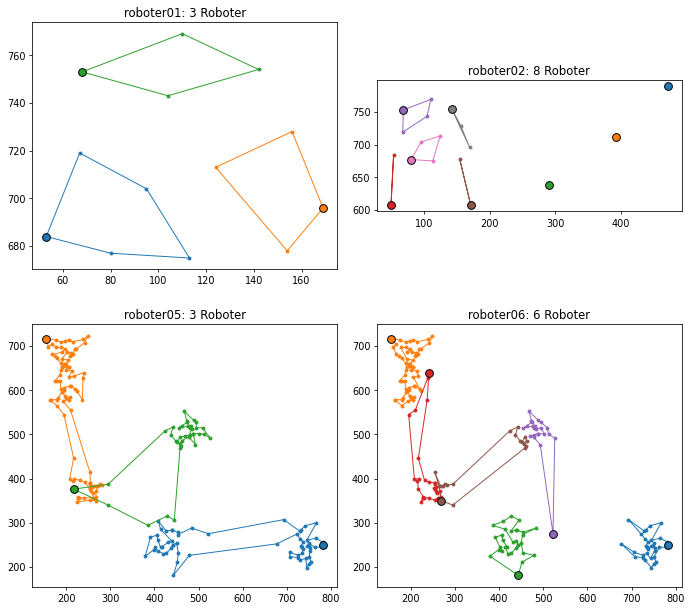

In [ ]:
import matplotlib.pyplot as plt


def zeichne(garten, routen, titel, achse):
    baeume = garten['baeume']
    farben = plt.rcParams['axes.prop_cycle'].by_key()['color']
    for k in range(len(routen)):
        xs = []
        ys = []
        for baum in routen[k] + [routen[k][0]]:               # zurück zum ersten Baum
            xs.append(baeume[baum][0])
            ys.append(baeume[baum][1])
        farbe = farben[k % len(farben)]
        achse.plot(xs, ys, '-o', color=farbe, markersize=3, linewidth=1)
        start = baeume[routen[k][0]]
        achse.plot([start[0]], [start[1]], 'o', color=farbe, markersize=8, markeredgecolor='black')
    achse.set_title(titel + ': ' + str(len(routen)) + ' Roboter')
    achse.set_aspect('equal')


fig, achsen = plt.subplots(2, 2, figsize=(10, 9))
for achse, nr in zip(achsen.flatten(), [1, 2, 5, 6]):
    garten, routen = ergebnisse[nr]
    zeichne(garten, routen, 'roboter' + str(nr).rjust(2, '0'), achse)
plt.tight_layout()
plt.show()

## Für Neugierige

**Warum ist die Aufgabe schwer?** Sie enthält das **Problem des Handlungsreisenden**: Hätte man nur einen Roboter mit sehr großer
Maximallänge, wäre die kürzeste Rundreise durch alle Bäume gesucht. Dazu kommt die Frage, **welche Bäume** zu welchem Roboter gehören.
Für beides ist kein schnelles exaktes Verfahren bekannt (die Aufgabe ist *NP-schwer*). Darum sind Näherungsverfahren (*Heuristiken*)
üblich, und man weiß am Ende nicht sicher, ob man die kleinste Zahl von Robotern gefunden hat.

**Bessere Rundreisen:** Für Routen mit wenigen Bäumen (etwa bis 15) findet der **Held-Karp-Algorithmus** (dynamische Programmierung
über Teilmengen) die kürzeste Rundreise exakt. Für größere gibt es die **3-opt**- und **Lin-Kernighan**-Heuristik, die mehr Kanten
gleichzeitig tauschen als unser 2-opt. Eine kürzere Route hat mehr Platz für weitere Bäume. Laut Tabelle 2 der Lösungshinweise
spart das bei den großen Beispielen 6 bis 30 Roboter gegenüber dem einfachen Greedy-Verfahren.

**Bessere Verteilung der Bäume:** Die Lösungshinweise benutzen für das Umverteilen einen Algorithmus nach **Hartigan und Wong**,
ursprünglich ein Verfahren zum Bilden von Gruppen (*k-means*). Er verschiebt einzelne Bäume von einer Route in eine andere, wenn das
etwas verbessert, und gleicht so die Längen der Routen aus. Danach werden Routen gelöscht und die Bäume neu verteilt. Unser
`verbessere` ist eine einfache Variante davon.

**Zufall:** Mit einem zufälligen Startbaum statt immer dem äußersten bekommt man andere Einteilungen. Probiert man viele, ist oft
eine dabei, die einen Roboter weniger braucht. Das kostet nur Rechenzeit.

**Genau rechnen:** Mit einem Solver für **ganzzahlige lineare Optimierung (ILP)** wie Gurobi kann man für eine Auswahl von Bäumen die
kürzeste Rundreise exakt berechnen. Das nutzen die Lösungshinweise zum Vergleich. Auch **MiniZinc** kann solche Probleme prinzipiell
beschreiben. Ein einfaches Modell, in dem jeder Roboter eine Folge von Bäumen fährt, liefert bei uns aber schon bei `roboter01.txt`
mit nur 13 Bäumen in einer Minute weder mit Gecode noch mit Chuffed eine Antwort. Für diese Aufgabe sind eigene Verfahren besser.

**Laufzeit:** Dank des Gitters schaut jeder Baum nur auf seine Nachbarn und nicht auf alle Bäume. Ohne Gitter müsste man bei 20 000
Bäumen für jeden Startbaum 20 000 Abstände ausrechnen und wäre bei `roboter11.txt` viel länger beschäftigt.